# 04 — Export for Deployment

**Project:** Driver Drowsiness Detection System
**Goal of this notebook (Step 4):** package the model chosen in Step 3 — the **Custom CNN** — into the files the FastAPI backend loads, and prove the export works.

| | |
|---|---|
| **Input** | `model/saved_models/custom_cnn.keras`, `model/artifacts/data_config.json`, `model/results/metrics.json` |
| **Output 1** | `model/exported/drowsiness_cnn.keras` — the deployment model (inference only) |
| **Output 2** | `model/exported/model_config.json` — class order, input size and preprocessing the backend must follow |

The backend (`backend/`) loads these two files **directly from `model/exported/`** — no copy of the model is kept inside the backend folder.

**Steps:** 1. Setup → 2. Configuration → 3. Load the chosen model → 4. Export the model → 5. Export the config → 6. Sanity check → 7. Summary

## 1. Setup

In [1]:
import json, time, datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from PIL import Image

# The notebook runs from the model/ folder, so the project root is one level up
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "model" else Path.cwd()
print("Project root:", PROJECT_ROOT)
print("TensorFlow  :", tf.__version__, "| Keras:", keras.__version__)

Project root: D:\MyProj\Clg\DLL Proj1
TensorFlow  : 2.21.0 | Keras: 3.13.2


## 2. Configuration

`CHOSEN_MODEL` is the model selected at the Step 3 checkpoint. The exported file gets a deployment name (`drowsiness_cnn.keras`), so the backend does not depend on training-time file names.

In [2]:
MODEL_DIR     = PROJECT_ROOT / "model"
ARTIFACTS_DIR = MODEL_DIR / "artifacts"
SAVED_DIR     = MODEL_DIR / "saved_models"
RESULTS_DIR   = MODEL_DIR / "results"
EXPORT_DIR    = MODEL_DIR / "exported"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

CHOSEN_MODEL = "custom_cnn"            # decided in Step 3 (notebook 03)
EXPORT_MODEL = EXPORT_DIR / "drowsiness_cnn.keras"
EXPORT_CONFIG = EXPORT_DIR / "model_config.json"

data_config = json.loads((ARTIFACTS_DIR / "data_config.json").read_text())
metrics = json.loads((RESULTS_DIR / "metrics.json").read_text())["models"][CHOSEN_MODEL]
CLASSES, IMG_SIZE = data_config["classes"], data_config["img_size"]
print(f"Exporting '{CHOSEN_MODEL}' | test accuracy {metrics['accuracy']:.2%} | classes {CLASSES}")

Exporting 'custom_cnn' | test accuracy 98.61% | classes ['Closed', 'Open', 'no_yawn', 'yawn']


## 3. Load the chosen model

The trained model as saved by notebook 02 (best epoch of run 3).

In [3]:
trained = keras.models.load_model(SAVED_DIR / f"{CHOSEN_MODEL}.keras")
print(f"Loaded {CHOSEN_MODEL}.keras | {trained.count_params():,} parameters | "
      f"{(SAVED_DIR / f'{CHOSEN_MODEL}.keras').stat().st_size / 1e6:.2f} MB")

Loaded custom_cnn.keras | 390,884 parameters | 4.78 MB


## 4. Export the model

The training file also stores the **optimizer state** (Adam keeps two extra values per weight), which is only needed to continue training. For deployment we wrap the same layers in a fresh, **un-compiled** `keras.Model` and save that — same weights, same predictions, about a third of the size.

Kept inside the model, as designed:
- **Augmentation layers** — automatically inactive at inference, so they change nothing.
- **`Rescaling(1/255)`** — the backend sends raw `0–255` RGB pixels and the model normalizes them itself.

In [4]:
deploy_model = keras.Model(trained.inputs, trained.outputs, name="drowsiness_cnn")  # same layers, no optimizer
deploy_model.save(EXPORT_MODEL)
print(f"Saved {EXPORT_MODEL.name}: {EXPORT_MODEL.stat().st_size / 1e6:.2f} MB "
      f"(training file was {(SAVED_DIR / f'{CHOSEN_MODEL}.keras').stat().st_size / 1e6:.2f} MB)")

Saved drowsiness_cnn.keras: 1.65 MB (training file was 4.78 MB)


## 5. Export the configuration

Everything the backend needs to prepare an image **exactly** like training did, in one small JSON file:

- **`classes`** — output index → class name (`0 = Closed`, `1 = Open`, `2 = no_yawn`, `3 = yawn`)
- **`img_size`, `color_mode`, `resize`, `input_range`** — resize to 128×128 with TensorFlow's bilinear `tf.image.resize` (exactly what `image_dataset_from_directory` did in training), RGB channel order (OpenCV reads BGR, so the backend must convert), raw `0–255` values
- **`eye_classes` / `yawn_classes`** — which outputs belong to eye crops and which to full frames (see notebook 01, Section 6)
- **`test_metrics`** — the Step 3 result, so the deployed model's quality is documented next to it

In [5]:
model_config = {
    "exported": datetime.date.today().isoformat(),
    "source_model": f"model/saved_models/{CHOSEN_MODEL}.keras",
    "model_file": EXPORT_MODEL.name,
    "classes": CLASSES,
    "img_size": IMG_SIZE,
    "color_mode": "rgb",
    "resize": "tf.image.resize(..., method='bilinear') on the full image to img_size x img_size (same as training)",
    "input_range": "raw 0-255 float32, shape (batch, img_size, img_size, 3); the model rescales internally",
    "eye_classes": ["Closed", "Open"],
    "yawn_classes": ["no_yawn", "yawn"],
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "test_metrics": {k: metrics[k] for k in ("accuracy", "f1_macro", "accuracy_leak_free", "cpu_latency_ms")},
}
EXPORT_CONFIG.write_text(json.dumps(model_config, indent=2))
print(json.dumps(model_config, indent=2))

{
  "exported": "2026-10-02",
  "source_model": "model/saved_models/custom_cnn.keras",
  "model_file": "drowsiness_cnn.keras",
  "classes": [
    "Closed",
    "Open",
    "no_yawn",
    "yawn"
  ],
  "img_size": 128,
  "color_mode": "rgb",
  "resize": "tf.image.resize(..., method='bilinear') on the full image to img_size x img_size (same as training)",
  "input_range": "raw 0-255 float32, shape (batch, img_size, img_size, 3); the model rescales internally",
  "eye_classes": [
    "Closed",
    "Open"
  ],
  "yawn_classes": [
    "no_yawn",
    "yawn"
  ],
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "test_metrics": {
    "accuracy": 0.9861,
    "f1_macro": 0.9861,
    "accuracy_leak_free": 0.9849,
    "cpu_latency_ms": 3.25
  }
}


## 6. Sanity check — reload the export and predict

To prove the export works, we load **both exported files fresh from disk** (as the backend will), then for one test image of each class:

1. preprocess it using **only** `model_config.json` (RGB, TensorFlow bilinear resize, raw pixels) — this is the recipe the backend will copy,
2. predict with the exported model,
3. compare with the original training model — the probabilities must be **identical** (up to float rounding).

Closed   -> predicted Closed   (100.00%)  | same as training model: True
Open     -> predicted Open     (100.00%)  | same as training model: True
no_yawn  -> predicted no_yawn  (89.60%)  | same as training model: True
yawn     -> predicted yawn     (100.00%)  | same as training model: True


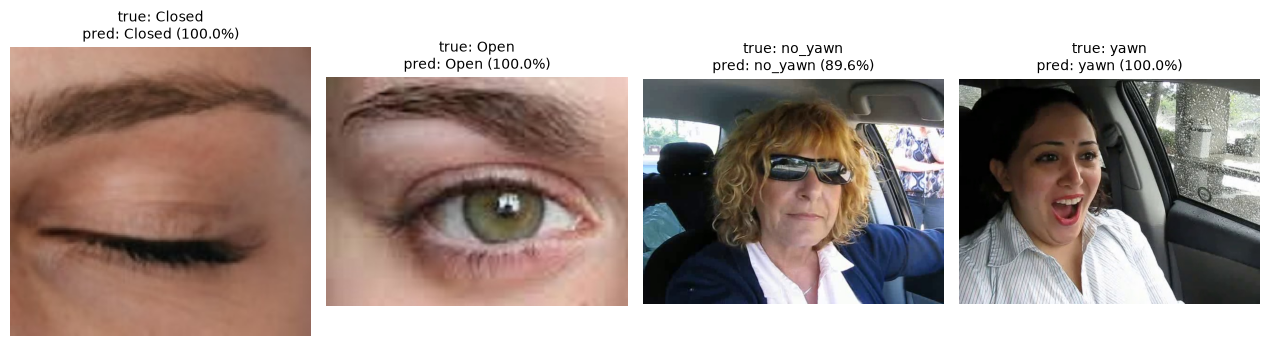


Sanity check passed: the exported model reproduces the training model exactly.


In [6]:
cfg = json.loads(EXPORT_CONFIG.read_text())
exported = keras.models.load_model(EXPORT_DIR / cfg["model_file"])


def prepare(path: Path) -> np.ndarray:
    # Preprocess one image exactly as model_config.json describes: RGB, tf bilinear resize, raw 0-255, batch of 1.
    rgb = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)
    return tf.image.resize(rgb, (cfg["img_size"], cfg["img_size"]), method="bilinear").numpy()[None]


test_dir = PROJECT_ROOT / data_config["paths"]["test"]
samples = {cls: sorted((test_dir / cls).iterdir())[0] for cls in cfg["classes"]}

fig, axes = plt.subplots(1, len(samples), figsize=(3.2 * len(samples), 3.6))
all_match = True
for ax, (cls, path) in zip(axes, samples.items()):
    x = prepare(path)
    p_export, p_train = exported.predict_on_batch(x)[0], trained.predict_on_batch(x)[0]
    match = np.allclose(p_export, p_train, atol=1e-6)
    all_match &= match
    pred = cfg["classes"][int(p_export.argmax())]
    print(f"{cls:<8} -> predicted {pred:<8} ({p_export.max():.2%})  | same as training model: {match}")
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"true: {cls}\npred: {pred} ({p_export.max():.1%})", fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()

assert all_match, "Exported model does not reproduce the training model's predictions!"
print("\nSanity check passed: the exported model reproduces the training model exactly.")

**Speed of the exported model** — one image on this CPU with the compiled predict path (median of 100), the way the backend will call it:

In [7]:
x = prepare(samples["Open"])
exported.predict_on_batch(x)  # warm-up
times = []
for _ in range(100):
    start = time.perf_counter()
    exported.predict_on_batch(x)
    times.append(time.perf_counter() - start)
print(f"Exported model: {np.median(times) * 1000:.2f} ms per image (target < 50 ms)")

Exported model: 4.78 ms per image (target < 50 ms)


## 7. Summary

- The **Custom CNN** (test accuracy 98.61 %) is exported to `model/exported/drowsiness_cnn.keras` without the optimizer state, together with `model/exported/model_config.json`.
- The sanity check reloads both files from disk, preprocesses images using only the config, and reproduces the training model's predictions exactly.

**Next → Step 5:** the FastAPI backend in `backend/` loads these two files from `model/exported/` once at startup and serves `/predict`, `/predict-stream` and `/health`.